# 10. Error analysis, drift, inference and tests

**The question this notebook answers:** where does the model go wrong, what happens when it is fed bad or missing data, has the 2016 population moved away from what it was validated on, and does the scoring code a credit officer would use (`predict.py`) give a fast, explained, trustworthy answer?

**What the brief asks:**
1. **Error analysis:** segments with **poor calibration**, the **most confident wrong predictions**, and behaviour on **missing or out-of-range inputs**.
2. **Drift:** score the **2016 holdout** and compute **PSI for the PD distribution and the top 10 inputs** against the 2015 validation set; **state what you would alert on**.
3. **`predict.py`** (function and CLI): one raw application plus its bureau record as JSON in; `pd`, `decision`, `model_version` and `reason_codes` out, the reasons being **the top 3 to 4 factors pushing PD up, in plain words a credit officer could give a declined customer**.
4. **Tests:** parity on `reference_transforms.csv`, input validation, threshold logic, reason codes, and **refusing a model with a mismatched `contract_version`**. **Latency:** p50 and p95.

Sections 1 and 2 present the tables written by `scripts/b2_error_analysis_and_drift.py` (which also writes `outputs/holdout_scores.csv`); sections 3 to 6 run the code live. This notebook shows only aggregates and made-up applicants, never a real loan.

**Terms used in this notebook**
- **Calibration gap:** observed default rate minus the average predicted PD, in a group of loans. Positive means the model under-predicts risk there.
- **Binomial test with Holm correction:** is a group's observed default count plausible if the PD were right? Testing about 40 groups at once, some would look off by chance; the Holm correction raises the bar to allow for that.
- **PSI (Population Stability Index):** how far a distribution has moved between two sets of loans. Under 0.10 stable, 0.10 to 0.25 investigate, 0.25 or more act.
- **Reason code:** a plain-language statement of one thing about the application that raised its PD, compared with a typical approved applicant.
- **SHAP value:** for a tree model, the exact amount each input adds to this applicant's log-odds of default; the values add up to the model's output.
- **p50 / p95 latency:** half of the calls are faster than p50; 95 in 100 are faster than p95.

In [1]:
import os, json, subprocess, sys, tempfile, time, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display

from credit_risk.model import policy
from credit_risk.model.data import load_config, split, training_frames
from credit_risk.model.models import add_grade_rank
from credit_risk.model.predict import ContractVersionMismatch, Predictor
from credit_risk.spec import ContractViolation

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)

cfg = load_config("config/train.yaml")
B2 = Path("reports/b2_error_analysis_and_drift")
predictor = Predictor()          # the same object the CLI, the tests and the Hugging Face demo use
EXAMPLES = {n: json.loads(Path(f"examples/{n}.json").read_text()) for n in ["low_risk", "borderline", "high_risk"]}
print("model version:", predictor.model_version)

model version: scorecard_boosted_average-contract1.0.0-2026-11-02-4d83cf8


## 1. Where the model fails

### Segments with poor calibration
Each group of at least 300 loans in 2015 (term, grade, purpose, home ownership, verification, region, income band, loan-size quarter, FICO band, job group), tested as above:

In [2]:
seg = pd.read_csv(B2 / "tables/calibration_by_segment_2015.csv")
overall_gap = 0.2009 - 0.1847   # observed minus predicted on all of 2015 (notebook 09)
print(f"{len(seg)} segments tested; verdicts: {seg.verdict.value_counts().to_dict()}")
print(f"overall gap on 2015: {overall_gap:+.3f}\n")
seg["gap_beyond_overall"] = seg.gap - overall_gap
print(seg[seg.verdict != "calibrated"].sort_values("gap", ascending=False)[["segment", "level", "loans", "predicted", "observed", "gap", "gap_beyond_overall", "holm_p", "verdict"]].round(3).to_string(index=False))

45 segments tested; verdicts: {'calibrated': 29, 'under-predicts risk': 16}
overall gap on 2015: +0.016

             segment                  level  loans  predicted  observed   gap  gap_beyond_overall  holm_p             verdict
           job_group                missing    968      0.191     0.256 0.065               0.049   0.000 under-predicts risk
       purpose_group          other_purpose    668      0.186     0.242 0.057               0.040   0.009 under-predicts risk
           job_group trades_transport_labor   1740      0.208     0.248 0.039               0.023   0.003 under-predicts risk
               grade                      D   2263      0.290     0.323 0.033               0.017   0.019 under-predicts risk
           job_group        executive_owner   1793      0.158     0.191 0.033               0.017   0.007 under-predicts risk
home_ownership_group                   RENT   6361      0.201     0.229 0.028               0.012   0.000 under-predicts risk
           fi

**Reading it.** Every flagged segment is **under**-predicted; none is over-predicted. Most of them are under-predicted by about the model's **overall** shortfall on 2015 (1.6 points, notebook 09): they are flagged because they are large, not because the model is wrong about them in particular. A handful stand out beyond that:
- **Job title missing** (+6.5 points), **trades, transport and labour** (+3.9) and **executives and owners** (+3.3). Job group is deliberately not a model input (restricted pending a fairness review, notebook 06), and this is the price: the model cannot see the extra risk. Whether to use it is a policy decision, and this table is the evidence for that discussion.
- **Purpose "other"** (+5.7) and **grade D** (+3.3): smaller groups where the 2015 rise in default was steeper.

What to do: recalibrate on the latest complete vintage before go-live (it removes the shared shortfall), and track these segments' gaps in monitoring.

### The most confident wrong predictions
Loans that defaulted although the model gave them a PD below 6%, and loans that repaid although it gave them above 40%, described by the median of their fields (no individual loan is shown):

In [3]:
print(pd.read_csv(B2 / "tables/confident_errors_profile.csv").set_index("median_of").to_string())
print()
band = pd.read_csv(B2 / "tables/observed_vs_predicted_by_pd_band_2015.csv")
print(band[["pd_band", "loans", "predicted", "observed"]].round(3).to_string(index=False))

                               all 2015 loans  defaulted although PD below 6%  repaid although PD above 40%
median_of                                                                                                  
term                                    36.00                           36.00                         60.00
annual_inc                           65000.00                        87000.00                      58000.00
dti_treated                             18.24                           13.58                         23.16
fico_mid_treated                       687.00                          717.00                        677.00
revol_util_treated                      53.60                           37.40                         61.55
credit_history_months_treated          180.00                          216.50                        171.00
loan_amnt                            12500.00                        12125.00                      18000.00
inq_last_6mths_capped       

**Reading it.** The confident misses look exactly like the applicants the model was right to trust or distrust: the low-PD defaulters have higher income, lower debt-to-income, higher FICO, lower utilisation and longer credit histories than the typical 2015 borrower; the high-PD payers are 60-month borrowers with weaker profiles. Nothing in the application separates them from their neighbours. This is the **irreducible part** of default: job loss, illness or divorce after the loan is issued is not in the data. The PD-band table puts it in proportion: of 911 loans with a PD under 4%, 2.2% defaulted, and the model said 3.2%. A low PD means unlikely, not impossible.

## 2. Behaviour on missing and out-of-range inputs
A made-up borderline applicant (`examples/borderline.json`) was scored with one thing changed at a time:

In [4]:
stress = pd.read_csv(B2 / "tables/behaviour_on_missing_and_bad_inputs.csv").fillna("")
print(stress.to_string(index=False))
print("\ncrashes:", int(stress.result.str.startswith("CRASHED").sum()))

                                scenario                        result      pd change_vs_base decision                                                               message
                         nothing changed                        scored  0.0917            0.0   review                                                                      
                  employer title missing                        scored  0.0917            0.0   review                                                                      
               employment length missing                        scored  0.0956         0.0039   review                                                                      
        no months since last delinquency                        scored  0.0903        -0.0014   review                                                                      
           bank-card utilisation missing                        scored  0.0945         0.0028   review                                 

**Reading it.**
- **Nothing crashes.** Every input is either scored or refused with a message that says what to fix.
- **Missing optional fields are scored**, with small, sensible changes: the contract fills them as it did in training, and a missing-value flag carries the information that they were missing.
- **Impossible or out-of-product values are refused**: a negative income, a 48-month term, a loan under $1,000, a number sent as text, a removed required field.
- **Values that look mis-entered are refused in live scoring**: an income of 58 (thousands), a loan ten times its installment, a FICO range written backwards. The contract repairs these silently in historical data, but for a live application the right action is to correct the form, so `predict()` runs in strict mode by default.
- **Extreme but possible values are scored**: an income of $5 million is capped at the training percentile, so it lowers PD only modestly; a debt-to-income of 120 raises it.
- **One known limit:** utilisation sent as a fraction (0.55 instead of 55) is caught for a batch of at least 100 applications (notebook 08), but a single application cannot be told apart from a genuine 0.55% utilisation, so it is scored as such. The form in the demo states the unit; a production API should too.

## 3. The 2016 holdout: scores and drift against 2015

outputs/holdout_scores.csv: 5,000 rows, columns ['id', 'pd'], unique ids: True, missing PDs: 0, PD range 0.017 to 0.753

                         item         kind    psi               alert
              PD distribution model output 0.0102 stable (below 0.10)
               sub_grade_rank top-10 input 0.0174 stable (below 0.10)
                         term top-10 input 0.0106 stable (below 0.10)
recent_accounts_share_treated top-10 input 0.0160 stable (below 0.10)
                  dti_treated top-10 input 0.0025 stable (below 0.10)
             fico_mid_treated top-10 input 0.0041 stable (below 0.10)
           avg_cur_bal_capped top-10 input 0.0035 stable (below 0.10)
       loan_to_income_treated top-10 input 0.0114 stable (below 0.10)
         acc_open_past_24mths top-10 input 0.0116 stable (below 0.10)
       tot_hi_cred_lim_capped top-10 input 0.0050 stable (below 0.10)
installment_to_income_treated top-10 input 0.0114 stable (below 0.10)

         2015 validation  2016 holdout

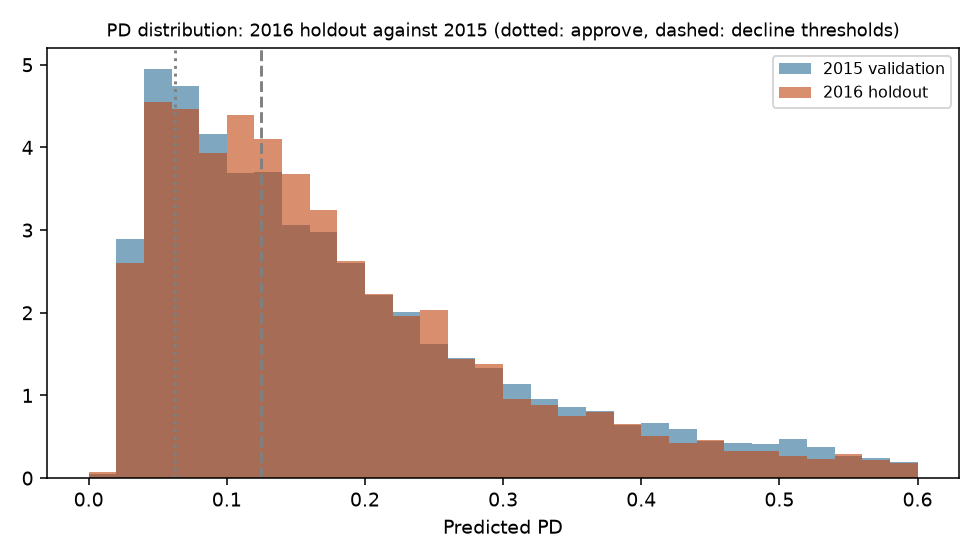

In [5]:
hold = pd.read_csv("outputs/holdout_scores.csv")
print(f"outputs/holdout_scores.csv: {len(hold):,} rows, columns {list(hold.columns)}, unique ids: {hold.id.is_unique}, missing PDs: {int(hold.pd.isna().sum())}, PD range {hold.pd.min():.3f} to {hold.pd.max():.3f}")
print()
print(pd.read_csv(B2 / "tables/holdout_drift_psi.csv").round(4).to_string(index=False))
print()
print(pd.read_csv(B2 / "tables/decision_mix_2015_vs_2016.csv").set_index("item").round(3).to_string())
display(Image(B2 / "figures/pd_distribution_2015_vs_2016.png", width=650))

**How the top 10 inputs were chosen:** by the average size of each input's contribution to the selected model's score on 2015 loans (the same contributions the reason codes use), so the list reflects this model, not a generic ranking. The platform's sub-grade is always monitored even if it were to fall out of the top 10, because the model depends on it.

**Reading it.** Everything is **stable**: PSI 0.010 for the PD distribution and at most 0.017 for any input. The 2016 applicants look like the 2015 ones, and the decision mix barely moves (approve 15.5% against 16.7%, mean PD 18.0% against 18.5%). The holdout has no labels, so this says the **population** is stable, not that the model is still accurate on it; accuracy can only be checked as 2016 loans mature.

### What I would alert on
| Signal | Investigate | Act (review or retrain) |
|---|---|---|
| PSI of the PD distribution, weekly against the validation year | 0.10 | 0.25 |
| PSI of each top-10 input and of the sub-grade mix | 0.10 | 0.25, or 0.10 on two inputs at once |
| Share approved, reviewed and declined | a move of 5 points | a move of 10 points |
| Early delinquency by monthly cohort (defaults take 36 to 60 months to show), then observed against predicted default as cohorts mature | gap above 2 points | gap above 4 points, or outside the 95% interval for two cohorts |
| Calibration gap of the segments in section 1 | above 5 points | above 8 points |
| Inputs refused, repaired, or outside the fitted caps | above 1% of applications | a sudden jump (a form or upstream system changed) |
| Scoring latency p95 | above 70 ms | above 100 ms |

The PSI levels are those set in `DESIGN.md` section 9; the other levels are my proposals, to be tuned once real monitoring data exists. The sub-grade deserves a separate line: if the platform changes how it grades, the model's main input changes meaning overnight. Its mix and the default rate by grade band are checked at every release, and the independent scorecard (`platform_score: none`) is the fallback.

## 4. `predict.py`: one application in, a decision with reasons out
The function:

In [6]:
for name, rec in EXAMPLES.items():
    print(f"--- {name} (made-up applicant)")
    print(json.dumps(predictor.predict(rec), indent=2))

--- low_risk (made-up applicant)
{
  "pd": 0.0208,
  "decision": "approve",
  "model_version": "scorecard_boosted_average-contract1.0.0-2026-11-02-4d83cf8",
  "reason_codes": []
}
--- borderline (made-up applicant)
{
  "pd": 0.0917,
  "decision": "review",
  "model_version": "scorecard_boosted_average-contract1.0.0-2026-11-02-4d83cf8",
  "reason_codes": [
    "Platform risk sub-grade: B4 (typical approved applicant: A4)"
  ]
}
--- high_risk (made-up applicant)
{
  "pd": 0.7205,
  "decision": "decline",
  "model_version": "scorecard_boosted_average-contract1.0.0-2026-11-02-4d83cf8",
  "reason_codes": [
    "Platform risk sub-grade: E4 (typical approved applicant: A4)",
    "Loan term (months): 60 (typical approved applicant: 36)",
    "Share of accounts opened in the last 24 months: 50% (typical approved applicant: 10%)",
    "Debt-to-income ratio: 31% (typical approved applicant: 13%)"
  ]
}


And the command line, which calls the same function:

In [7]:
out = subprocess.run([sys.executable, "-m", "credit_risk.model.predict", "--json", "examples/borderline.json"], capture_output=True, text=True)
print("$ uv run python -m credit_risk.model.predict --json examples/borderline.json")
print(out.stdout)
assert json.loads(out.stdout) == predictor.predict(EXAMPLES["borderline"])   # the CLI and the function agree

$ uv run python -m credit_risk.model.predict --json examples/borderline.json
{
  "pd": 0.0917,
  "decision": "review",
  "model_version": "scorecard_boosted_average-contract1.0.0-2026-11-02-4d83cf8",
  "reason_codes": [
    "Platform risk sub-grade: B4 (typical approved applicant: A4)"
  ]
}



**Reading it.** The three made-up applicants land in the three bands. The `model_version` names the model, the contract version, the training date and the commit, so any decision can be traced to the exact code and data. The reasons are written for the applicant, each with their own value and the typical approved applicant's next to it, and a reason appears only if it raises the odds of default by about 10% or more. So a low-risk applicant may get none, and at most four are given.

### Are the reasons faithful to the model?
The selected model averages two models in log-odds. Each member's contribution is measured against the same reference, the training applicants the model approves. That makes the contributions add up **exactly** to the applicant's log-odds minus the reference's, so the reasons explain the actual score, not an approximation of it.

In [8]:
_, _, frame = training_frames(cfg)
train = add_grade_rank(split(frame, end=cfg["fit_cutoff"]))
model = predictor.bundle.model
approved = train[policy.decide(predictor.bundle.score(train), predictor.bundle.thresholds) == "approve"]
logit = lambda p: np.log(p / (1 - p))
avg_logit = lambda df: np.mean([logit(m.predict(df)) for m in model.members], axis=0)
for name, rec in EXAMPLES.items():
    row = predictor.frame(rec)
    contrib = model.contributions(row)[0]
    lhs, rhs = contrib.sum(), avg_logit(row)[0] - avg_logit(approved).mean()
    top = pd.Series(contrib, index=model.columns).sort_values(ascending=False).head(3)
    print(f"{name:<11} sum of contributions {lhs:+.6f} | log-odds minus the approved applicants' average {rhs:+.6f} | largest: " + ", ".join(f"{c} {v:+.2f}" for c, v in top.items()))
print(f"\nreference group: {len(approved):,} approved training applicants ({predictor.bundle.metadata['reference_group']})")

low_risk    sum of contributions -0.703218 | log-odds minus the approved applicants' average -0.703218 | largest: factor_public_records +0.02, open_acc +0.00, total_rev_hi_lim_capped +0.00
borderline  sum of contributions +0.738333 | log-odds minus the approved applicants' average +0.738333 | largest: sub_grade_rank +0.48, avg_cur_bal_capped +0.08, fico_mid_treated +0.04
high_risk   sum of contributions +3.562100 | log-odds minus the approved applicants' average +3.562100 | largest: sub_grade_rank +1.38, term +0.45, recent_accounts_share_treated +0.19

reference group: 2,181 approved training applicants (2,181 training loans the model approves)


**Reading it.** The two columns agree to six decimals for every applicant: nothing is hidden or rounded away. The largest contributions are the ones turned into reason codes, in the same order. For the high-risk applicant, the sub-grade leads (the platform also rated them risky), followed by the specific facts the officer can talk about. A test (`test_the_averaged_model_explains_exactly_what_it_predicts`) checks this property on every run.

### A model built on another contract is refused
If someone pairs a model with a contract it was not trained on (for example, after the data scientist changes a bin), the scores would be silently wrong. `Predictor` refuses to load it:

In [9]:
bundle = joblib.load("models/pd_model.joblib")
bundle.metadata = {**bundle.metadata, "contract_version": "2.0.0"}
with tempfile.TemporaryDirectory() as d:
    joblib.dump(bundle, Path(d) / "other_contract.joblib")
    try:
        Predictor(Path(d) / "other_contract.joblib")
        print("loaded (unexpected)")
    except ContractVersionMismatch as e:
        print("refused:", e)

refused: model built on contract 2.0.0, transform is 1.0.0, spec is 1.0.0


## 5. The tests
The brief names five things to test. Each has its own tests, and the whole suite runs in seconds:

In [10]:
brief = {
    "parity on reference_transforms.csv": "tests/test_contract.py::test_the_committed_contract_passes_the_parity_check",
    "input validation": "tests/test_spec.py::test_bad_inputs_fail_fast_with_a_clear_message",
    "threshold logic": "tests/test_policy_metrics.py::test_decision_logic_at_the_boundaries",
    "reason codes": "tests/test_model.py::test_reason_codes_are_few_plain_and_only_for_factors_that_raise_risk",
    "mismatched contract_version refused": "tests/test_model.py::test_a_model_built_on_another_contract_version_is_refused",
}
for what, test in brief.items():
    print(f"{what:<38} {test}")
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:warnings"], capture_output=True, text=True)
print("\n$ uv run pytest -q\n" + r.stdout.strip().splitlines()[-1])

parity on reference_transforms.csv     tests/test_contract.py::test_the_committed_contract_passes_the_parity_check
input validation                       tests/test_spec.py::test_bad_inputs_fail_fast_with_a_clear_message
threshold logic                        tests/test_policy_metrics.py::test_decision_logic_at_the_boundaries
reason codes                           tests/test_model.py::test_reason_codes_are_few_plain_and_only_for_factors_that_raise_risk
mismatched contract_version refused    tests/test_model.py::test_a_model_built_on_another_contract_version_is_refused



$ uv run pytest -q
142 passed in 15.71s


Beyond those five: the cleaning, treatment, WoE and factor code of Part A; that 2015 loans change nothing that was fitted; that nothing from the servicing file reaches the model; the selection rule; that the demo gives the same PD as `predict()`; and that one application scores the same alone as in a batch.

## 6. Latency
The brief allows 100 ms per application. A quick measurement here (the full benchmark, with a breakdown by step, is `scripts/b3_benchmark_latency.py`, written to `reports/latency.md`):

In [11]:
rec = EXAMPLES["borderline"]
for _ in range(10):
    predictor.predict(rec)
t = []
for _ in range(200):
    s = time.perf_counter(); predictor.predict(rec); t.append((time.perf_counter() - s) * 1000)
print(f"this run: p50 {np.percentile(t, 50):.1f} ms, p95 {np.percentile(t, 95):.1f} ms over 200 calls (validation, transform, two models, calibration and reasons)")
print()
print("\n".join(l for l in Path("reports/latency.md").read_text().splitlines() if l.startswith("|")))

this run: p50 44.1 ms, p95 49.9 ms over 200 calls (validation, transform, two models, calibration and reasons)

| What | p50 (ms) | p95 (ms) | p99 (ms) | max (ms) |
|---|---|---|---|---|
| full predict(), low_risk | 42.9 | 48.9 | 74.5 | 80.6 |
| full predict(), borderline | 43.1 | 48.7 | 72.9 | 74.2 |
| full predict(), high_risk | 43.6 | 48.8 | 74.4 | 78.8 |
| step: input validation (raw) | 1.7 | 1.9 | 3.6 | 3.7 |
| step: contract transform (cleaning ... WoE) | 21.4 | 22.8 | 51.5 | 52.4 |
| step: validation of the cleaned values | 7.6 | 8.0 | 8.3 | 40.3 |
| step: score (model + calibration) | 3.7 | 4.1 | 4.6 | 5.3 |
| step: reason codes | 3.4 | 4.0 | 5.4 | 35.8 |


**Reading it.** A full call takes about 43 ms at the median and under 50 ms at the 95th percentile, half the budget. About half of it is the contract transform (cleaning, features, WoE, PCA and factors); the two models and the reasons take a few milliseconds each. The Hugging Face demo runs the same code on a shared CPU, which is slower, but the budget leaves room. A test fails if the median of 20 calls reaches 100 ms.

## Summary: what the brief asked, and where it is answered

| Brief item | Answered in |
|---|---|
| Segments with poor calibration | section 1 |
| Most confident wrong predictions | section 1 |
| Behaviour on missing or out-of-range inputs | section 2 |
| Score the 2016 holdout (`outputs/holdout_scores.csv`: id, pd) | section 3 |
| PSI of the PD distribution and the top 10 inputs, 2016 against 2015 | section 3 |
| What to alert on | section 3 (the alert table) |
| `predict.py`, function and CLI: pd, decision, model_version, reason_codes | section 4 |
| Reason codes in plain words, top 3 to 4 factors pushing PD up | section 4 |
| Tests: parity, validation, thresholds, reason codes, contract version | sections 4 and 5 |
| Latency p50 and p95 | section 6 (`reports/latency.md`) |